In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('HousingData.csv')

print("First 5 rows:")
print(df.head())
print("\nDataset info:")
print(df.info())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nSummary statistics:")
print(df.describe())
print("\nshape")
print(df.shape)

First 5 rows:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622    3  222     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90    NaN  36.2  

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NO

In [ ]:
for col in df.columns:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f"Filled {col} with median: {median_val}")

# Verify no more missing values
print("\nMissing values after fixing:")
print(df.isnull().sum())

print(df.shape)

Filled CRIM with median: 0.253715
Filled ZN with median: 0.0
Filled INDUS with median: 9.69
Filled CHAS with median: 0.0
Filled AGE with median: 76.80000000000001
Filled LSTAT with median: 11.43

Missing values after fixing:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64
(506, 14)


/tmp/ipykernel_38640/3417372709.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)


In [ ]:
# Check the distribution of these columns
print("ZN value counts:")
print(df['ZN'].value_counts().head(10))
print(f"\nPercentage of ZN that is 0: {(df['ZN'] == 0).mean() * 100:.1f}%")

print("CHAS value counts:")
print(df['CHAS'].value_counts())
print(f"\nPercentage of CHAS that is 0: {(df['CHAS'] == 0).mean() * 100:.1f}%")

ZN value counts:
ZN
0.0     380
20.0     20
80.0     14
22.0     10
25.0     10
12.5     10
45.0      6
40.0      6
30.0      5
90.0      5
Name: count, dtype: int64

Percentage of ZN that is 0: 75.1%
CHAS value counts:
CHAS
0.0    472
1.0     34
Name: count, dtype: int64

Percentage of CHAS that is 0: 93.3%


In [11]:
# Separate features (X) and target (y)
# MEDV is the house price (in $1000s)
X = df.drop('MEDV', axis=1)
y = df['MEDV']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget (MEDV) - house prices in $1000s:")
print(f"Min: ${y.min():.0f}K, Max: ${y.max():.0f}K, Mean: ${y.mean():.0f}K")

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("\nAfter standardization:")
print(f"Mean of CRIM: {X_scaled['CRIM'].mean():.10f}")
print(f"Std of CRIM: {X_scaled['CRIM'].std():.2f}")

Features shape: (506, 13)
Target shape: (506,)

Target (MEDV) - house prices in $1000s:
Min: $5K, Max: $50K, Mean: $23K

After standardization:
Mean of CRIM: -0.0000000000
Std of CRIM: 1.00


In [13]:
# Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42
)

print(f"Training set: {X_train.shape[0]} houses")
print(f"Test set: {X_test.shape[0]} houses")
print(f"Number of features: {X_train.shape[1]}")

Training set: 404 houses
Test set: 102 houses
Number of features: 13


In [15]:
# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Calculate metrics
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_test)

print(f"R-squared (Train): {r2_train:.4f}")
print(f"R-squared (Test): {r2_test:.4f}")
print(f"Mean Squared Error: ${mse:.2f}")
print(f"Root Mean Squared Error: ${rmse:.2f}K")
print(f"Mean Absolute Error: ${mae:.2f}K")

R-squared (Train): 0.7426
R-squared (Test): 0.6591
Mean Squared Error: $25.00
Root Mean Squared Error: $5.00K
Mean Absolute Error: $3.15K


In [16]:
# Calculate percentage error
y_pred_test = model.predict(X_test)
percentage_errors = np.abs((y_test - y_pred_test) / y_test) * 100
avg_percentage_error = percentage_errors.mean()

print(f"Average prediction is off by: {avg_percentage_error:.1f}%")

Average prediction is off by: 16.5%


In [19]:
# Create coefficients dataframe
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
coef_df['Abs_Coefficient'] = abs(coef_df['Coefficient'])
coef_df = coef_df.sort_values('Abs_Coefficient', ascending=False)

print(f"\nIntercept (baseline price): ${model.intercept_:.2f}K")
print("\nTop 10 most important features (impact on price in $1000s):")

for i in range(10):
    feature = coef_df.iloc[i]['Feature']
    coef = coef_df.iloc[i]['Coefficient']
    direction = "INCREASES" if coef > 0 else "DECREASES"
    print(f"{i+1}. {feature}: {coef:+.4f}")
    print(f"   For 1 std dev increase, price {direction} by ${abs(coef)*1000:.0f}")


Intercept (baseline price): $22.46K

Top 10 most important features (impact on price in $1000s):
1. RM: +3.3111
   For 1 std dev increase, price INCREASES by $3311
2. DIS: -3.1685
   For 1 std dev increase, price DECREASES by $3169
3. LSTAT: -3.1137
   For 1 std dev increase, price DECREASES by $3114
4. PTRATIO: -1.9249
   For 1 std dev increase, price DECREASES by $1925
5. RAD: +1.8982
   For 1 std dev increase, price INCREASES by $1898
6. NOX: -1.8497
   For 1 std dev increase, price DECREASES by $1850
7. TAX: -1.5245
   For 1 std dev increase, price DECREASES by $1525
8. B: +1.0975
   For 1 std dev increase, price INCREASES by $1097
9. CRIM: -0.9639
   For 1 std dev increase, price DECREASES by $964
10. CHAS: +0.8210
   For 1 std dev increase, price INCREASES by $821


Bigger houses (RM) = more money

More crime (CRIM) = less money

Better schools (PTRATIO) = more money (lower ratio = better schools)

Near the river (CHAS) = more money

More pollution (NOX) = less money

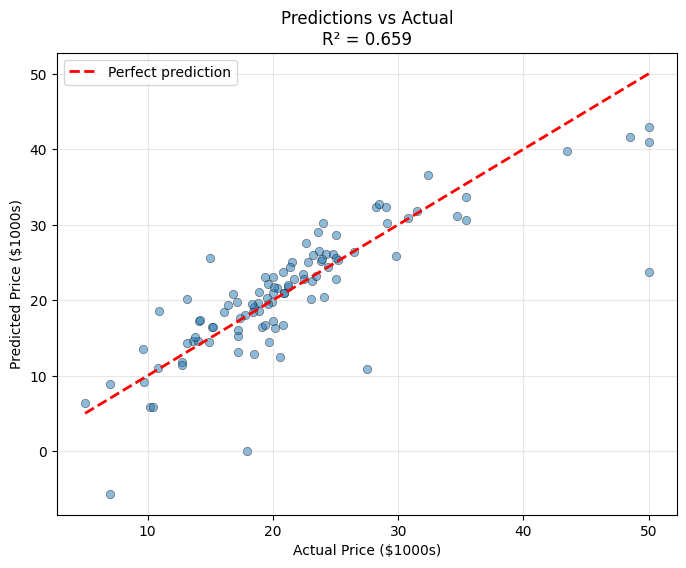

In [25]:
#Predictions vs Actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_test, alpha=0.5, edgecolors='black', linewidth=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect prediction')
plt.xlabel('Actual Price ($1000s)')
plt.ylabel('Predicted Price ($1000s)')
plt.title(f'Predictions vs Actual\nR² = {r2_test:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

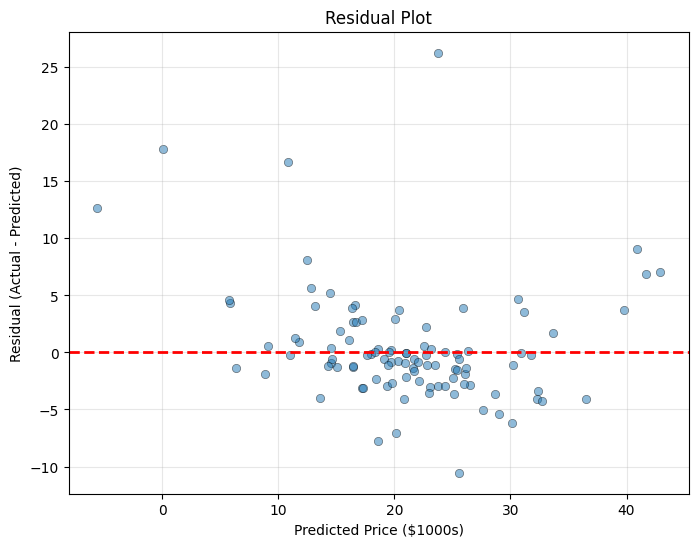

In [24]:
#Residuals (errors)
residuals = y_test - y_pred_test

plt.figure(figsize=(8, 6))
plt.scatter(y_pred_test, residuals, alpha=0.5, edgecolors='black', linewidth=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Price ($1000s)')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Plot')
plt.grid(True, alpha=0.3)
plt.show()

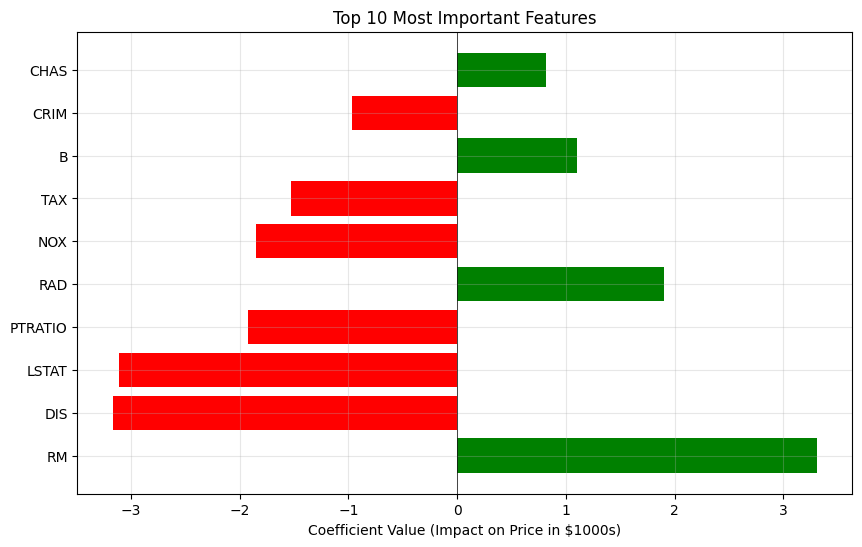

In [26]:
#Top 10 most important features
top10 = coef_df.head(10)
colors = ['green' if x > 0 else 'red' for x in top10['Coefficient']]

plt.figure(figsize=(10, 6))
plt.barh(range(len(top10)), top10['Coefficient'], color=colors)
plt.yticks(range(len(top10)), top10['Feature'])
plt.xlabel('Coefficient Value (Impact on Price in $1000s)')
plt.title('Top 10 Most Important Features')
plt.axvline(x=0, color='black', linewidth=0.5)
plt.grid(True, alpha=0.3)
plt.show()